In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Dense, Dropout,
    BatchNormalization, GlobalAveragePooling1D
)
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000


In [3]:
x_train = pad_sequences(
    x_train, maxlen=max_length,
    padding="post", truncating="post"
)

x_test = pad_sequences(
    x_test, maxlen=max_length,
    padding="post", truncating="post"
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [4]:
model = Sequential([
    Embedding(vocab_size, 128, input_length=max_length),

    GlobalAveragePooling1D(),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [6]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7388 - loss: 0.5245 - val_accuracy: 0.7670 - val_loss: 0.5620
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8766 - loss: 0.2960 - val_accuracy: 0.8680 - val_loss: 0.3226
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9041 - loss: 0.2392 - val_accuracy: 0.8550 - val_loss: 0.3594
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9208 - loss: 0.1996 - val_accuracy: 0.8484 - val_loss: 0.3791


In [8]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8493 - loss: 0.3504
Test Loss: 0.35042938590049744
Test Accuracy: 0.8493199944496155


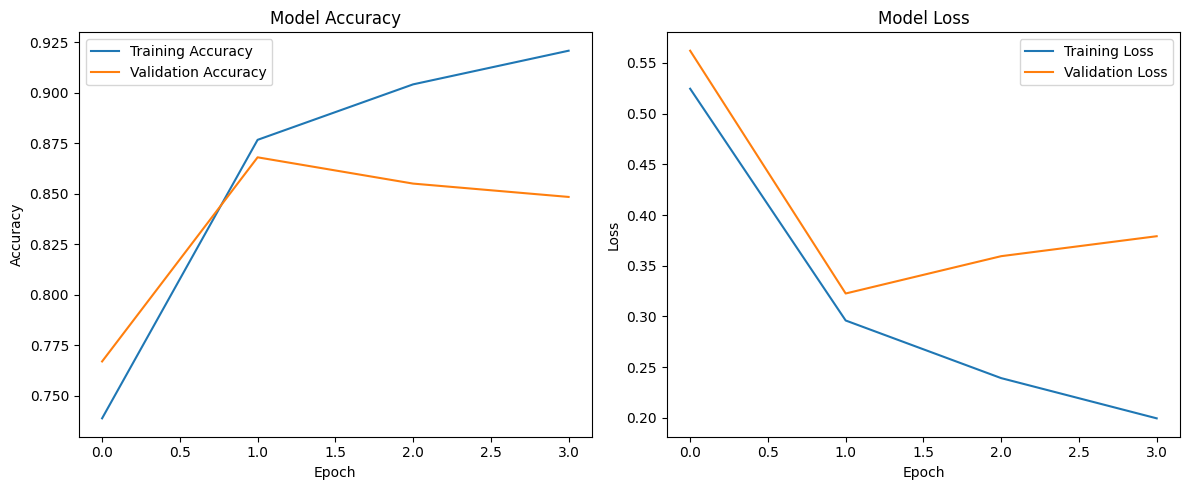

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("training_curves.png")
plt.show()

In [10]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    words = review.lower().split()

    # Convert words into the dataset's integer encoding
    sequence = [1]

    for word in words:
        index = word_index.get(word, 0) + 3

        if index >= vocab_size:
            index = 2

        sequence.append(index)

    padded = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability * 100
    else:
        sentiment = "Negative"
        confidence = (1 - probability) * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence: {:.2f}%".format(confidence))


predict_sentiment(
    "This movie was amazing and I really enjoyed it"
)

predict_sentiment(
    "This movie was boring and very disappointing"
)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Review: This movie was amazing and I really enjoyed it
Predicted Sentiment: Positive
Confidence: 78.95%
Review: This movie was boring and very disappointing
Predicted Sentiment: Negative
Confidence: 50.96%


In [11]:
model.save("sentiment_model.keras")
print("Model saved successfully!")

Model saved successfully!
